# Cell counts per cell line

Counts the single cells that each cell line contributes to the atlas after single-cell quality control (QC), for each plate (time point).

**Why:** the number of cells per cell line and time point tells how much data each line has, and the cell lines with few cells are the ones to treat with care in later analyses.

**Input:** `4.preprocess_features/qc_report/qc_report_per_plate.csv`, which has the number of single cells of every cell line and plate before QC and the number that failed QC.
The cells that pass QC are the cells in the `*_sc_feature_selected.parquet` profiles, and the notebook checks that the totals match.

**Output:** `results/0.cell_counts/cell_counts_per_cell_line_and_plate.csv` with one row per cell line and plate.
The notebook also plots the cells of each cell line as a bar chart, colored by tissue site and grouped by cancer group. The chart is shown in the notebook and is not saved to disk.

| Column | Description |
| --- | --- |
| `cell_line`, `plate`, `time_point` | Cell line name (as in the platemaps), plate barcode, and hours after seeding. |
| `total_single_cells` | Single cells segmented before QC. |
| `failed_qc` | Cells removed by QC (clustered nuclei, low solidity nuclei, or cells with multiple nuclei). |
| `cells_after_qc` | Cells kept in the profiles (`total_single_cells - failed_qc`). |
| `percentage_failing_qc` | `failed_qc` as a percentage of `total_single_cells`. |
| `cancer_type`, `cancer_group`, `tissue_site`, `origin` | Cell line annotations from `cell_lines/`. |

A cell line has no row for a plate that was not processed (CHLA262 at 72 h, Saos-2 at 24 h, and CF1500 and X0092 on all plates; see `3.cp_analysis`).

## Import libraries

In [1]:
import pathlib

import matplotlib.pyplot as plt
import pandas as pd
import pyarrow.parquet as pq
from matplotlib.patches import Patch
from matplotlib.ticker import StrMethodFormatter
from pccma_utils.cell_lines import load_cell_line_groups
from pccma_utils.palettes import site_colors

## Set paths

In [2]:
qc_report_path = pathlib.Path("../4.preprocess_features/qc_report/qc_report_per_plate.csv")
metadata_path = pathlib.Path("../cell_lines/pccma_cell_line_metadata.csv")
groups_path = pathlib.Path("../cell_lines/plotting_helpers/cancer_type_categories.yaml")

# single-cell feature-selected profiles, used only to check the counts
local_dir = pathlib.Path("../4.preprocess_features/data/single_cell_profiles")
bandicoot_dir = pathlib.Path("~/mnt/bandicoot/PCCMA_data/Atlas_v2_profiles/single_cell_profiles").expanduser()
profile_dir = local_dir if any(local_dir.glob("*_sc_feature_selected.parquet")) else bandicoot_dir

results_dir = pathlib.Path("./results/0.cell_counts")
results_dir.mkdir(parents=True, exist_ok=True)

## Cell counts per cell line and plate

In [4]:
qc_report = pd.read_csv(qc_report_path).rename(columns={
    "Image_Metadata_Plate": "plate",
    "total_failed_qc": "failed_qc",
    "percentage_failing_cells": "percentage_failing_qc",
})
qc_report["cells_after_qc"] = qc_report["total_single_cells"] - qc_report["failed_qc"]

counts = qc_report[["cell_line", "plate", "time_point", "total_single_cells", "failed_qc", "cells_after_qc", "percentage_failing_qc"]].merge(
    load_cell_line_groups(metadata_path, groups_path), on="cell_line", how="left"
)

assert not counts.duplicated(["cell_line", "plate"]).any(), "a cell line and plate appears more than once"
assert counts["cancer_group"].notna().all(), "a cell line has no cancer group"

counts = counts.sort_values(["cancer_group", "cell_line", "time_point"]).reset_index(drop=True)
counts.to_csv(results_dir / "cell_counts_per_cell_line_and_plate.csv", index=False)
print(f"{counts['cell_line'].nunique()} cell lines, {len(counts)} cell line and plate combinations")

54 cell lines, 166 cell line and plate combinations


## Check against the profiles

The cells after QC of each plate should equal the number of rows in that plate's single-cell profiles.

In [5]:
after_qc = counts.groupby("plate")["cells_after_qc"].sum()
for plate, n_cells in after_qc.items():
    n_rows = pq.ParquetFile(profile_dir / f"{plate}_sc_feature_selected.parquet").metadata.num_rows
    assert n_cells == n_rows, f"{plate}: {n_cells} cells after QC in the report but {n_rows} rows in the profiles"
print("The cell counts match the single-cell profiles of all", len(after_qc), "plates")

The cell counts match the single-cell profiles of all 9 plates


## Summary

In [6]:
print("Cells after QC per time point:")
print(counts.groupby("time_point")["cells_after_qc"].agg(["sum", "median", "min", "max"]).rename(columns={"sum": "total"}).to_string())

per_line = counts.groupby("cell_line")["cells_after_qc"].sum().sort_values()
print(f"\nCells after QC per cell line (all time points): median {per_line.median():,.0f}, from {per_line.min():,} ({per_line.index[0]}) to {per_line.max():,} ({per_line.index[-1]})")
print(f"Cell line and plate combinations with fewer than 1,000 cells: {(counts['cells_after_qc'] < 1000).sum()}")

Cells after QC per time point:
             total  median  min    max
time_point                            
24          297920  3783.0  290  22579
48          373645  4501.0  136  22722
72          533147  5824.0  334  41469

Cells after QC per cell line (all time points): median 17,537, from 760 (CHLA196) to 70,809 (TC71)
Cell line and plate combinations with fewer than 1,000 cells: 15


## Cells per cell line

A bar chart of the cells after QC of each cell line (all time points together), to scan the data set at a glance.
The bars are colored by tissue site, with the count at the end of each bar, and the cell lines are grouped by cancer group (the number of cell lines is in brackets).
The chart is displayed here and not saved to disk.

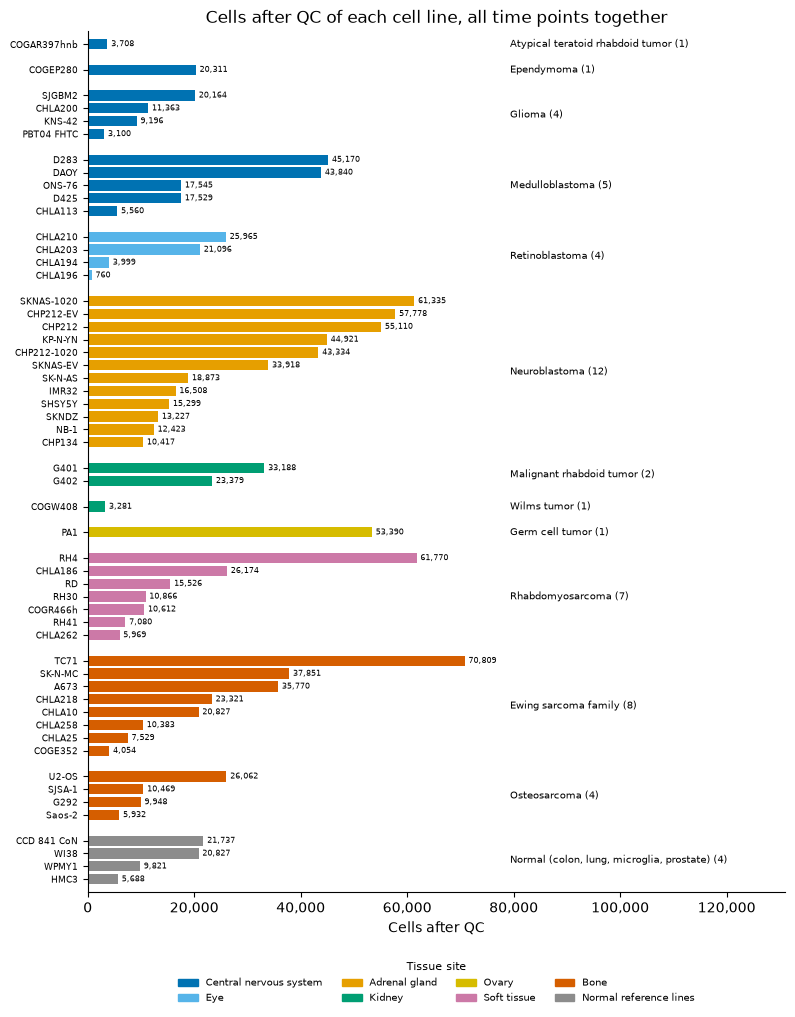

In [3]:
per_line = counts.groupby(["tissue_site", "cancer_group", "cell_line"], as_index=False)["cells_after_qc"].sum()
per_line["site_rank"] = per_line["tissue_site"].map({site: rank for rank, site in enumerate(site_colors)})
per_line = per_line.sort_values(["site_rank", "cancer_group", "cells_after_qc"], ascending=[True, True, False]).reset_index(drop=True)

# one row per cell line, with a gap between cancer groups
new_group = per_line["cancer_group"] != per_line["cancer_group"].shift()
per_line["row"] = per_line.index + new_group.cumsum()

fig, ax = plt.subplots(figsize=(9, 0.17 * len(per_line) + 2))
ax.barh(per_line["row"], per_line["cells_after_qc"], color=per_line["tissue_site"].map(site_colors), height=0.8)
ax.set_yticks(per_line["row"], per_line["cell_line"], fontsize=6.5)

most_cells = per_line["cells_after_qc"].max()

# the actual count at the end of each bar
for _, line in per_line.iterrows():
    ax.text(line["cells_after_qc"] + most_cells * 0.01, line["row"], f"{line['cells_after_qc']:,}", va="center", fontsize=6)

# the cancer group (and its number of cell lines) to the right of the counts
for group, group_rows in per_line.groupby("cancer_group", sort=False):
    ax.text(most_cells * 1.12, group_rows["row"].mean(), f"{group} ({len(group_rows)})", va="center", fontsize=7)

ax.set_xlim(0, most_cells * 1.85)
ax.set_ylim(per_line["row"].max() + 1, per_line["row"].min() - 1)  # first cancer group on top
ax.xaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
ax.set(title="Cells after QC of each cell line, all time points together", xlabel="Cells after QC")
ax.spines[["top", "right"]].set_visible(False)
ax.legend(
    handles=[Patch(color=color, label=site) for site, color in site_colors.items() if site in set(per_line["tissue_site"])],
    title="Tissue site", ncol=4, fontsize=7, title_fontsize=8, frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.07),
)
plt.show()